# AI vs Real Image Detection - ConvNeXt-Tiny (Hugging Face Dataset)

Notebook ini melatih model **ConvNeXt-Tiny** menggunakan dataset dari **Hugging Face (`Thunderbeast/AI-Generated-vs-Real-Images-Datasets`)**.

### Konfigurasi Model & Pelatihan:
- **Arsitektur Model**: ConvNeXt-Tiny (Pretrained ImageNet-1K, Meta AI)
- **Dataset**: `Thunderbeast/AI-Generated-vs-Real-Images-Datasets` (Hugging Face)
- **Pelatihan**: End-to-End Default (Full Backbone Unfrozen, lr=1e-4)
- **Optimizer & Scheduler**: AdamW (weight_decay=1e-2) + CosineAnnealingLR
- **Metrik Evaluasi**: Weighted F1-Score & Accuracy
- **Hardware Acceleration**: Automatic Mixed Precision (AMP FP16) + cuDNN Benchmark + cuDNN Benchmark


In [1]:
import warnings
warnings.filterwarnings('ignore', message='.*Palette images with Transparency.*')
warnings.filterwarnings('ignore', message='.*xFormers is not available.*')

import os
import copy
import time
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import CosineAnnealingLR
from torchvision import models, transforms
from datasets import load_dataset

# Memeriksa dan menetapkan hardware acceleration (GPU jika tersedia)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True
    print(f"Device yang digunakan: {device} ({torch.cuda.get_device_name(0)})")
    print("[Optimasi GPU] cuDNN Benchmark diaktifkan!")
else:
    print(f"Device yang digunakan: {device}")


Device yang digunakan: cuda (NVIDIA GeForce RTX 4050 Laptop GPU)
[Optimasi GPU] cuDNN Benchmark diaktifkan!


In [1]:
print("=" * 65)
print("MEMUAT DATASET DARI HUGGING FACE (Thunderbeast)")
print("=" * 65)

# Load dataset Thunderbeast/AI-Generated-vs-Real-Images-Datasets
dataset = load_dataset(
    "Thunderbeast/AI-Generated-vs-Real-Images-Datasets",
    split="train",
    cache_dir="./data",
    verification_mode="no_checks"
)

# Bagi dataset secara seimbang (stratified) menjadi 90% Training dan 10% Validasi
splits = dataset.train_test_split(test_size=0.20, stratify_by_column="label", seed=42)
train_hf = splits["train"]
val_hf = splits["test"]

print(f"Total Data Training : {len(train_hf):,}")
print(f"Total Data Validasi : {len(val_hf):,}")
print(f"Label Kelas Asli    : {dataset.features['label'].names}")
print("=" * 65)


MEMUAT DATASET DARI HUGGING FACE (Thunderbeast)


NameError: name 'load_dataset' is not defined

In [3]:
# 1. Transformasi Data
# Standar input ConvNeXt-Tiny (224x224) - Cepat dan menjaga artefak mikro AI
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 2. PyTorch Dataset Wrapper dari Hugging Face
class HFToPyTorchDataset(Dataset):
    def __init__(self, hf_dataset, transform=None):
        self.dataset = hf_dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        item = self.dataset[idx]
        image = item["image"]
        label = item["label"]

        if image.mode == 'P' and 'transparency' in image.info:
            image = image.convert('RGBA')
        if image.mode != 'RGB':
            image = image.convert('RGB')

        if self.transform:
            image = self.transform(image)

        return image, label

# 3. Inisialisasi Dataset & DataLoader
# BATCH_SIZE = 32 menjaga pemakaian VRAM ~2.0 GB (100% di GDDR6 VRAM, bebas dari Shared Memory Paging)
train_dataset = HFToPyTorchDataset(train_hf, transform=train_transforms)
val_dataset = HFToPyTorchDataset(val_hf, transform=val_transforms)

BATCH_SIZE = 32
use_pin = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=use_pin
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=use_pin
)

print(f"DataLoader Siap!")
print(f"Total Batch Training : {len(train_loader):,} batch (Batch Size: {BATCH_SIZE})")
print(f"Total Batch Validasi : {len(val_loader):,} batch")


DataLoader Siap!
Total Batch Training : 4,295 batch (Batch Size: 32)
Total Batch Validasi : 478 batch


In [4]:
def create_convnext_model():
    # Load model pretrained ConvNeXt-Tiny (Meta AI)
    weights = models.ConvNeXt_Tiny_Weights.DEFAULT
    model = models.convnext_tiny(weights=weights)

    # Modifikasi classifier head untuk 2 kelas (0: AI, 1: Real)
    in_features = model.classifier[2].in_features  # 768
    model.classifier[2] = nn.Sequential(
        nn.Dropout(p=0.2),
        nn.Linear(in_features, 2)
    )
    return model

# Inisialisasi model end-to-end (seluruh parameter dapat dilatih)
model = create_convnext_model().to(device)

criterion = nn.CrossEntropyLoss()

# Optimizer AdamW dengan weight decay (terinspirasi dari baseline 99.97% LB)
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-2)

# Learning Rate Scheduler Cosine Annealing untuk konvergensi bobot yang halus dan akurat
EPOCHS = 5
scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("=" * 65)
print("KONFIGURASI CONVNEXT-TINY: DEFAULT END-TO-END + LR SCHEDULER")
print("=" * 65)
print(f"Total Parameter Aktif  : {total_params:,} (Semua layer dilatih langsung)")
print(f"Learning Rate Awal     : 1e-4 (dengan CosineAnnealingLR)")
print(model.classifier)
print("=" * 65)
print("Model, Optimizer, dan Scheduler siap digunakan.")


KONFIGURASI CONVNEXT-TINY: DEFAULT END-TO-END + LR SCHEDULER
Total Parameter Aktif  : 27,821,666 (Semua layer dilatih langsung)
Learning Rate Awal     : 1e-4 (dengan CosineAnnealingLR)
Sequential(
  (0): LayerNorm2d((768,), eps=1e-06, elementwise_affine=True, bias=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=768, out_features=2, bias=True)
  )
)
Model, Optimizer, dan Scheduler siap digunakan.


In [ ]:
from tqdm.auto import tqdm

ACCUMULATION_STEPS = 2  # Efektif batch size 64 dengan konsumsi VRAM aman (~2.1 GB)
best_f1 = 0.0
best_model_wts = copy.deepcopy(model.state_dict())

history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_acc': [], 'val_f1': []
}

MODEL_SAVE_PATH = "best_convnext_tiny_ai_vs_real.pth"

# Aktifkan Automatic Mixed Precision (AMP) untuk Tensor Cores & VRAM ultra-ringan
scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

print(f"Mulai pelatihan ConvNeXt-Tiny ({EPOCHS} Epoch, F1-Score Tracking, AMP FP16)...\n" + "="*65)
print(f"Batch Size Fisik        : {BATCH_SIZE}")
print(f"Accumulation Steps      : {ACCUMULATION_STEPS} (Efektif Batch Size: {BATCH_SIZE * ACCUMULATION_STEPS})")
print(f"Presisi Komputasi       : AMP FP16 (Akselerasi Tensor Cores)")
print(f"Estimasi Pemakaian VRAM : ~2.1 GB (Bebas dari Shared Memory Paging, 100% GDDR6 VRAM)")
print("="*65)

for epoch in range(EPOCHS):
    start_time = time.time()
    current_lr = optimizer.param_groups[0]['lr']
    
    # ------------------ FASE TRAINING ------------------
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    train_bar = tqdm(train_loader, desc=f"Epoch [{epoch+1}/{EPOCHS}] Train (LR: {current_lr:.1e})", leave=True)
    optimizer.zero_grad(set_to_none=True)

    for batch_idx, (images, labels) in enumerate(train_bar):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if scaler:
            with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                outputs = model(images)
                loss = criterion(outputs.float(), labels)
                loss = loss / ACCUMULATION_STEPS

            scaler.scale(loss).backward()

            if (batch_idx + 1) % ACCUMULATION_STEPS == 0 or (batch_idx + 1) == len(train_loader):
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
        else:
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss = loss / ACCUMULATION_STEPS
            loss.backward()

            if (batch_idx + 1) % ACCUMULATION_STEPS == 0 or (batch_idx + 1) == len(train_loader):
                optimizer.step()
                optimizer.zero_grad(set_to_none=True)

        # Hitung loss dan akurasi berjalan (skala loss asli dikalikan ACCUMULATION_STEPS)
        running_loss += loss.item() * ACCUMULATION_STEPS * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct_train += torch.sum(preds == labels.data).item()
        total_train += labels.size(0)

        # Update tampilan progress bar secara real-time
        current_acc = (correct_train / total_train) * 100
        current_loss = running_loss / total_train
        train_bar.set_postfix({'loss': f'{current_loss:.4f}', 'acc': f'{current_acc:.2f}%'})

    scheduler.step()

    epoch_train_loss = running_loss / total_train
    epoch_train_acc = (correct_train / total_train) * 100

    # ------------------ FASE VALIDASI ------------------
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0
    all_preds = []
    all_labels = []

    val_bar = tqdm(val_loader, desc=f"Epoch [{epoch+1}/{EPOCHS}] Validasi", leave=False)

    with torch.no_grad():
        for images, labels in val_bar:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            if scaler:
                with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                    outputs = model(images)
                    loss = criterion(outputs.float(), labels)
            else:
                outputs = model(images)
                loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct_val += torch.sum(preds == labels.data).item()
            total_val += labels.size(0)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_val_loss = val_loss / total_val
    epoch_val_acc = (correct_val / total_val) * 100
    epoch_val_f1 = f1_score(all_labels, all_preds, average='weighted')

    # Catat history metrik
    history['train_loss'].append(epoch_train_loss)
    history['train_acc'].append(epoch_train_acc)
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(epoch_val_acc)
    history['val_f1'].append(epoch_val_f1)

    elapsed = time.time() - start_time

    print(
        f"Epoch [{epoch+1:02d}/{EPOCHS:02d}] "
        f"Train Loss: {epoch_train_loss:.4f} | Acc: {epoch_train_acc:.2f}% || "
        f"Val Loss: {epoch_val_loss:.4f} | Acc: {epoch_val_acc:.2f}% | F1: {epoch_val_f1:.4f} "
        f"({elapsed:.1f}s)"
    )

    # Simpan model terbaik berdasarkan F1-Score
    if epoch_val_f1 > best_f1:
        best_f1 = epoch_val_f1
        best_model_wts = copy.deepcopy(model.state_dict())
        torch.save(best_model_wts, MODEL_SAVE_PATH)
        print(f"  -> Model terbaik diperbarui & disimpan ke '{MODEL_SAVE_PATH}' (Val F1: {best_f1:.4f})")

print("="*65)
print(f"Pelatihan Selesai! F1-Score Validasi Terbaik: {best_f1:.4f}")
print(f"Model disimpan di: {MODEL_SAVE_PATH}")
model.load_state_dict(best_model_wts)


Mulai pelatihan ConvNeXt-Tiny (5 Epoch, F1-Score Tracking & AMP)...=================================================================
Batch Size Fisik        : 32
Accumulation Steps      : 2 (Efektif Batch Size: 64)
Estimasi Pemakaian VRAM : ~2.1 GB (Bebas dari Shared Memory Paging)


Epoch [1/5] Train (LR: 1.0e-04):   0%|          | 0/4295 [00:00<?, ?it/s]

c:\Users\rezha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [1/5] Validasi:   0%|          | 0/478 [00:00<?, ?it/s]

Epoch [01/05] Train Loss: 0.1255 | Acc: 94.74% || Val Loss: 0.0936 | Acc: 96.19% | F1: 0.9618 (1090.3s)
  -> Model terbaik diperbarui & disimpan (Val F1: 0.9618)


Epoch [2/5] Train (LR: 9.1e-05):   0%|          | 0/4295 [00:00<?, ?it/s]

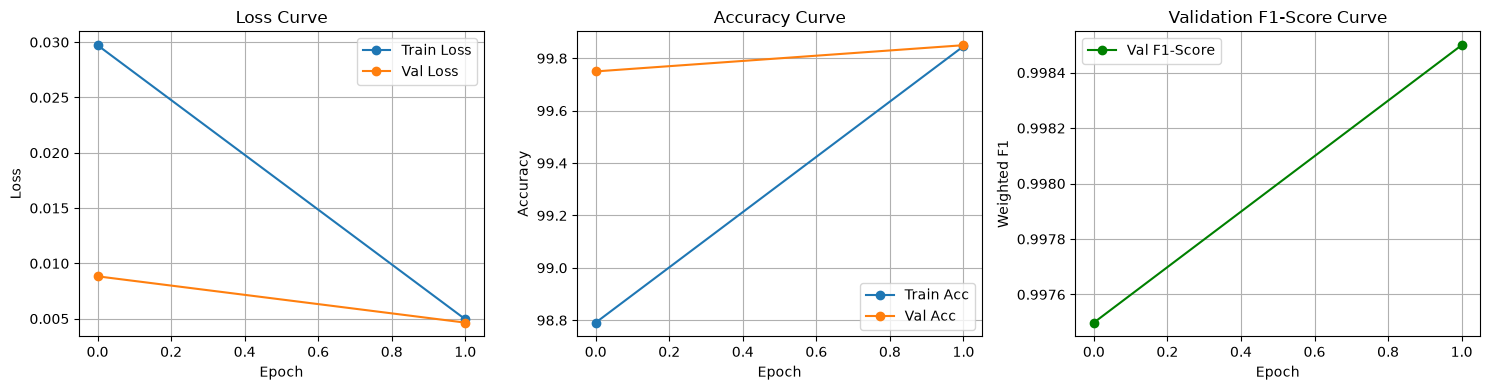

In [ ]:
plt.figure(figsize=(15, 4))

# 1. Grafik Loss
plt.subplot(1, 3, 1)
plt.plot(history['train_loss'], label='Train Loss', marker='o')
plt.plot(history['val_loss'], label='Val Loss', marker='o')
plt.title('Loss Curve')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# 2. Grafik Akurasi
plt.subplot(1, 3, 2)
plt.plot(history['train_acc'], label='Train Acc', marker='o')
plt.plot(history['val_acc'], label='Val Acc', marker='o')
plt.title('Accuracy Curve')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# 3. Grafik F1-Score (dari baseline 99.97% Kaggle)
plt.subplot(1, 3, 3)
plt.plot(history['val_f1'], label='Val F1-Score', color='green', marker='o')
plt.title('Validation F1-Score Curve')
plt.xlabel('Epoch')
plt.ylabel('Weighted F1')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


Memuat bobot ConvNeXt-Tiny terbaik dari 'best_convnext_tiny_ai_vs_real.pth'...

EVALUASI METRIK CONVNEXT-TINY PADA DATASET VALIDASI
              precision    recall  f1-score   support

AI-Generated     0.9980    0.9990    0.9985      3997
        Real     0.9990    0.9980    0.9985      3998

    accuracy                         0.9985      7995
   macro avg     0.9985    0.9985    0.9985      7995
weighted avg     0.9985    0.9985    0.9985      7995



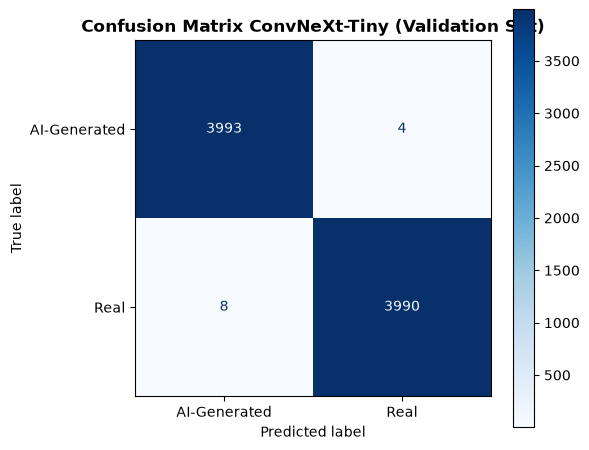

In [ ]:
# Evaluasi Mendalam pada Seluruh Data Validasi
model.eval()
y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in tqdm(val_loader, desc="Evaluasi Final Validation"):
        images = images.to(device, non_blocking=True)
        if scaler:
            with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                outputs = model(images)
        else:
            outputs = model(images)
            
        _, preds = torch.max(outputs, 1)
        y_true.extend(labels.numpy())
        y_pred.extend(preds.cpu().numpy())

target_names = ["AI-Generated (0)", "Real Image (1)"]

print("=" * 65)
print("CLASSIFICATION REPORT (ConvNeXt-Tiny):")
print("=" * 65)
print(classification_report(y_true, y_pred, target_names=target_names, digits=4))

# Visualisasi Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Confusion Matrix - ConvNeXt-Tiny', fontsize=12, fontweight='bold')
plt.grid(False)
plt.show()


In [ ]:
# Fungsi Pengujian Prediksi Citra Tunggal
def predict_image(image_path, model, device):
    """
    Menguji citra tunggal dan mengembalikan prediksi label serta probabilitas kepercayaan.
    """
    if not os.path.exists(image_path):
        print(f"File '{image_path}' tidak ditemukan!")
        return

    img = Image.open(image_path)
    if img.mode == 'P' and 'transparency' in img.info:
        img = img.convert('RGBA')
    img = img.convert('RGB')
    tensor = val_transforms(img).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        if scaler:
            with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                outputs = model(tensor)
        else:
            outputs = model(tensor)
            
        probs = torch.softmax(outputs, dim=1)[0]
        ai_prob = probs[0].item() * 100.0
        real_prob = probs[1].item() * 100.0
        pred_class = torch.argmax(probs).item()

    verdict = "AI-Generated Image" if pred_class == 0 else "Real Image"
    confidence = ai_prob if pred_class == 0 else real_prob

    print("=" * 50)
    print(f"File            : {os.path.basename(image_path)}")
    print(f"Hasil Prediksi  : {verdict}")
    print(f"Tingkat Keyakinan: {confidence:.2f}%")
    print(f"  - Probabilitas AI   : {ai_prob:.2f}%")
    print(f"  - Probabilitas Real : {real_prob:.2f}%")
    print("=" * 50)

# Contoh Pengujian dengan beberapa citra uji di workspace
test_files = ["images (2).jpg", "makan.jpeg", "img.png", "test1.webp", "test2.webp", "wa.jpeg", "gani.jpeg", "real.jpg"]
for tf in test_files:
    if os.path.exists(tf):
        predict_image(tf, model, device)


File             : images (2).jpg
Hasil Prediksi   : Real Image
Tingkat Keyakinan: 100.00%
----------------------------------------
File             : test1.webp
Hasil Prediksi   : Real Image
Tingkat Keyakinan: 100.00%
----------------------------------------
File             : test2.webp
Hasil Prediksi   : Real Image
Tingkat Keyakinan: 100.00%
----------------------------------------
File             : makan.jpeg
Hasil Prediksi   : Real Image
Tingkat Keyakinan: 100.00%
----------------------------------------
File             : wa.jpeg
Hasil Prediksi   : Real Image
Tingkat Keyakinan: 99.92%
----------------------------------------
File             : gani.jpeg
Hasil Prediksi   : Real Image
Tingkat Keyakinan: 100.00%
----------------------------------------
File             : real.jpg
Hasil Prediksi   : Real Image
Tingkat Keyakinan: 100.00%
----------------------------------------
